# Saturación de inversión en dos cuentas de Meta Ads

**La pregunta:** si una de estas dos cuentas recibe un euro más, ¿rinde igual que el anterior?

Es la pregunta que decide un presupuesto, y la respuesta habitual —partir los días en cuartiles
de inversión y mirar cómo cae el ROAS— da el resultado contrario al verdadero en una de las dos
cuentas. Este notebook recorre el camino entero: el análisis que sale mal, por qué sale mal, y la
corrección.

**Cómo leerlo.** Seis secciones, en el orden en que se hicieron:

| | |
|---|---|
| 1 | ¿Se puede confiar en estos datos? |
| 2 | La trampa del promedio de ratios |
| 3 | Rendimientos decrecientes: el análisis que sale mal |
| 4 | La corrección: medir dentro del mes |
| 5 | Una ruptura de serie que no es una mejora |
| 6 | ROAS medio y ROAS marginal no dicen lo mismo |

> **Los datos son sintéticos.** El análisis original se hizo sobre dos cuentas reales y esos datos
> no se pueden publicar. Lo que hay en `data/` lo genera `src/generar_datos.py`, calibrado para
> reproducir la estructura que el análisis tiene que detectar. Clientes, mercados y fechas son
> inventados. Las conclusiones de este notebook son conclusiones sobre estos datos; las del
> proyecto real están en el README.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DB = RAIZ / "data" / "processed" / "campanas.db"
RUTA_SQL = RAIZ / "sql" / "analisis"
INFORMES = RAIZ / "informes"
INFORMES.mkdir(exist_ok=True)

# Que los importes no salgan en notación científica y que las tablas no se
# partan en varias líneas.
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)


def consulta(nombre):
    """Ejecuta un archivo de sql/analisis/ y devuelve el resultado.

    El notebook no lleva SQL copiado dentro: lee los archivos. Así el archivo
    y el notebook no pueden decir cosas distintas.
    """
    sql = (RUTA_SQL / f"{nombre}.sql").read_text(encoding="utf-8")
    conexion = sqlite3.connect(RUTA_DB)
    try:
        return pd.read_sql_query(sql, conexion)
    finally:
        conexion.close()


conexion = sqlite3.connect(RUTA_DB)
try:
    df = pd.read_sql_query("SELECT * FROM v_metricas_diarias", conexion,
                           parse_dates=["fecha"])
finally:
    conexion.close()

print(f"{len(df):,} filas  ·  {df['fecha'].min():%Y-%m-%d} a {df['fecha'].max():%Y-%m-%d}")
df.head(3)

11,862 filas  ·  2024-01-01 a 2026-06-30


,fecha,cliente,pais,area,inversion_eur,impresiones,alcance,clics_enlace,clics_todos,compras,valor_compras,visitas_landing,roas,cpa,valor_medio_compra,cpc_enlace,cpm,ctr_enlace,tasa_conversion,compras_por_100eur
0,2024-01-01,Cliente A,ES,Kids,170.39,39095,24422,313,640,28,"1,142.42",240,6.70,6.09,40.80,0.54,4.36,0.80,8.95,16.43
1,2024-01-01,Cliente A,ES,Men,181.87,63612,24929,451,816,14,707.61,371,3.89,12.99,50.54,0.40,2.86,0.71,3.10,7.70
2,2024-01-01,Cliente A,ES,Women,516.20,148077,105330,1157,2479,51,"3,441.02",957,6.67,10.12,67.47,0.45,3.49,0.78,4.41,9.88


In [2]:
# Estilo de los gráficos. Un color fijo por cliente y por área, definido una
# sola vez: si un gráfico se queda sin un grupo, matplotlib desplaza su ciclo
# de colores y el mismo cliente sale de dos colores distintos en dos paneles.
AZUL, NARANJA, AGUA = "#257de0", "#f47230", "#00b894"
TINTA, TINTA_SUAVE = "#191919", "#666666"

COLOR_CLIENTE = {"Cliente A": AZUL, "Cliente B": NARANJA}
COLOR_AREA = {"Women": AZUL, "Men": NARANJA, "Kids": AGUA}

plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "savefig.dpi": 110,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#cfcfcf", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.labelsize": 9, "axes.labelcolor": TINTA_SUAVE,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#ebebeb", "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "font.size": 10, "text.color": TINTA,
})

---
## 1. ¿Se puede confiar en estos datos?

Antes de medir nada. Si el pipeline duplica filas o si hay días que no existen, cualquier
conclusión posterior es ruido bien presentado.

El primer control cuadra los totales de la vista contra los de la tabla. La vista solo agrega, así
que **puede cambiar el número de filas pero no los importes**. Un `GROUP BY` mal escrito duplicaría
filas sin dar ningún error y las cifras saldrían infladas: cuadrar contra un total conocido es lo
único que lo detecta.

In [3]:
consulta("00_cuadre_totales")

,origen,filas,inversion,ingresos,compras
0,campanas (tabla),20978,"4,940,179.46","41,984,722.23",788845
1,v_metricas_diarias,11862,"4,940,179.46","41,984,722.23",788845


In [4]:
consulta("01_calidad_datos")

,control,ambito,filas,pct_ingresos
0,compras sin impresiones,Cliente B,125,0.38
1,dias de calendario sin datos,Cliente A / ES,0,NaN
2,dias de calendario sin datos,Cliente B / DE,4,NaN
3,dias de calendario sin datos,Cliente B / ES,19,NaN
4,dias de calendario sin datos,Cliente B / FR,4,NaN
5,dias de calendario sin datos,Cliente B / IT,4,NaN
6,dias de calendario sin datos,Cliente B / NL,4,NaN
7,inversion 0 con ingresos,Cliente B,54,0.02


Tres rarezas, y lo que importa de cada una no es cuántas filas son sino **cuánto pesan sobre los
ingresos**:

- **Compras sin impresiones.** Imposible de leer como un embudo normal. Pesa un 0,4 % de los
  ingresos, así que no se tira ni se arregla: se deja documentada.
- **Inversión 0 con ingresos.** No es un error. Son compras atribuidas a clics de días anteriores,
  y es lo que explica el borde de cada pausa de la cuenta. Pesa poco en ingresos, pero **sí importa
  mucho en los cálculos de saturación**, porque un día con 0 € de inversión y 150 € de ingresos
  tiene un ROAS infinito e infla el tramo de poca inversión. Se filtran con `inversion_eur > 0`
  antes de cualquier cuartil.
- **Días de calendario sin datos.** Solo en el Cliente B. Hay que saber si son huecos de datos o
  pausas reales, porque la decisión es opuesta: un hueco no se puede interpretar, y una pausa es
  información. Un hueco **no se rellena con 0**, porque un 0 significa "se invirtió 0 €".

In [5]:
# Diagnóstico de los días que faltan en el mercado principal del Cliente B.
es = df[(df["cliente"] == "Cliente B") & (df["pais"] == "ES")]
dias_con_datos = pd.DatetimeIndex(sorted(es["fecha"].unique()))
calendario = pd.date_range(dias_con_datos.min(), dias_con_datos.max())
faltan = calendario.difference(dias_con_datos)

# Agrupar los días que faltan en bloques consecutivos. Un bloque seguido
# apunta a una pausa; días sueltos repartidos apuntan a un fallo de carga.
serie = faltan.to_series()
bloque = serie.diff().dt.days.ne(1).cumsum()
bloques = serie.groupby(bloque).agg(desde="min", hasta="max", dias="count")

# ¿Estaban activos los otros mercados del mismo cliente esos días? Si lo
# estaban, la pausa es solo de ES y no de la cuenta entera. La distinción
# decide qué series hay que excluir.
otros = df[(df["cliente"] == "Cliente B") & (df["pais"] != "ES")]
bloques["otros_mercados_activos"] = [
    otros[(otros["fecha"] >= d) & (otros["fecha"] <= h) & (otros["inversion_eur"] > 0)]
    ["pais"].nunique()
    for d, h in zip(bloques["desde"], bloques["hasta"])
]

# Inversión de ES justo antes del hueco: si cae a 0 poco a poco, es una pausa
# planificada y no un corte de datos.
bloques["inv_es_3_dias_antes"] = [
    es[(es["fecha"] >= d - pd.Timedelta(days=3)) & (es["fecha"] < d)]
    ["inversion_eur"].sum().round(2)
    for d in bloques["desde"]
]

print(f"{len(faltan)} días sin datos, en {len(bloques)} bloques")
bloques

19 días sin datos, en 4 bloques


,desde,hasta,dias,otros_mercados_activos,inv_es_3_dias_antes
1,2024-12-12,2024-12-15,4,0,0.00
2,2025-03-07,2025-03-14,8,4,0.00
3,2025-08-09,2025-08-12,4,4,0.00
4,2025-11-30,2025-12-02,3,4,0.00


No son huecos de datos: son **pausas**. Bloques seguidos de varios días, con el resto de los
mercados invirtiendo con normalidad, y con la inversión de ES ya casi a cero antes de empezar el
bloque.

Y no todas tienen el mismo alcance. El bloque en el que **ningún otro mercado está activo** es una
pausa de toda la cuenta, no de un mercado. Importa porque una pausa de mercado invalida solo las
series de ese mercado, y una de cuenta invalida cualquier serie del cliente.

Estos días quedan fuera de los cálculos de estacionalidad y de saturación.

---
## 2. La trampa del promedio de ratios

El ROAS de la vista es correcto fila a fila. Promediarlo no lo es, y el error no avisa.

In [6]:
comparacion = pd.DataFrame({
    "promedio de los ROAS diarios": df.groupby("cliente")["roas"].mean(),
    "ingresos totales / inversión total": (
        df.groupby("cliente")["valor_compras"].sum()
        / df.groupby("cliente")["inversion_eur"].sum()),
})
comparacion["error_pct"] = (comparacion.iloc[:, 0] / comparacion.iloc[:, 1] - 1) * 100
comparacion.round(2)

,promedio de los ROAS diarios,ingresos totales / inversión total,error_pct
cliente,,,
Cliente A,9.07,9.87,-8.11
Cliente B,9.02,8.04,12.13


Un 10 % de desvío. Poco para que nadie lo note en una reunión y suficiente para que una
recomendación se vaya al área equivocada.

Pero el error no está repartido por igual. Promediar ratios da el mismo peso a un día de 20 € que a
uno de 4.000 €, así que **el daño se concentra donde hay días de muy poca inversión**: justo los del
borde de cada pausa, que apenas gastan y aún reciben compras atribuidas a clics anteriores.

In [7]:
mensual_es = (df[(df["cliente"] == "Cliente B") & (df["pais"] == "ES")]
              .assign(mes=lambda t: t["fecha"].dt.to_period("M"))
              .groupby("mes")
              .agg(promedio_de_ratios=("roas", "mean"),
                   ingresos=("valor_compras", "sum"),
                   inversion=("inversion_eur", "sum"),
                   roas_maximo_del_mes=("roas", "max"),
                   dias_bajo_20eur=("inversion_eur", lambda s: (s < 20).sum()))
              .assign(correcto=lambda t: t["ingresos"] / t["inversion"]))
mensual_es["error_pct"] = (mensual_es["promedio_de_ratios"] / mensual_es["correcto"] - 1) * 100

peor = mensual_es.nlargest(5, "error_pct")
peor[["promedio_de_ratios", "correcto", "error_pct", "roas_maximo_del_mes", "dias_bajo_20eur"]].round(1)

,promedio_de_ratios,correcto,error_pct,roas_maximo_del_mes,dias_bajo_20eur
mes,,,,,
2025-03,22.50,11.00,105.20,327.40,14
2025-11,4.80,3.10,53.50,50.30,15
2025-12,5.00,3.80,32.90,26.70,6
2024-12,16.70,12.80,30.60,57.20,14
2025-01,9.90,8.50,16.90,29.30,0


En el mes de la pausa larga, el promedio de ratios dice **22,5 y el ROAS real es 11,0**: el error es
del 105 %. Lo produce un puñado de días con menos de 20 € de inversión y un ROAS de tres cifras, que
en la media pesan exactamente lo mismo que un martes normal de 2.000 €.

Y el número que sale de ahí **sigue pareciendo un ROAS perfectamente razonable**. Esa es la parte
peligrosa: no hay error, no hay aviso, solo una cifra creíble y falsa.

La regla: un ratio agregado se calcula sumando el numerador, sumando el denominador y dividiendo al
final. Nunca promediando ratios. Por eso todas las métricas derivadas viven en una sola vista
(`sql/vista_metricas.sql`) y ningún análisis las vuelve a calcular por su cuenta.

---
## 3. Rendimientos decrecientes: el análisis que sale mal

El método de libro: partir los días en cuartiles de inversión y mirar el ROAS de cada cuartil. Si
el ROAS cae del cuartil 3 al 4, la cuenta está saturando.

Se mira 2025, un año completo con los dos clientes activos, el mismo mercado y por área.

In [8]:
base = df[(df["pais"] == "ES")
          & (df["inversion_eur"] > 0)        # fuera los días de inversión 0
          & (df["fecha"].dt.year == 2025)].copy()

base["cuartil"] = (base.groupby(["cliente", "area"])["inversion_eur"]
                   .transform(lambda s: pd.qcut(s, 4, labels=["C1", "C2", "C3", "C4"])))
base["mes"] = base["fecha"].dt.to_period("M")

por_cuartil = (base.groupby(["cliente", "area", "cuartil"], observed=True)
               .agg(dias=("fecha", "nunique"),
                    inversion_dia=("inversion_eur", "mean"),
                    inversion=("inversion_eur", "sum"),
                    ingresos=("valor_compras", "sum"),
                    meses_distintos=("mes", "nunique"))
               .assign(roas=lambda t: t["ingresos"] / t["inversion"]))

por_cuartil[["dias", "inversion_dia", "roas", "meses_distintos"]]

dias  inversion_dia  roas  meses_distintos
cliente   area  cuartil                                            
Cliente A Kids  C1         92         171.38  8.32                4
                C2         91         224.40  9.62                5
                C3         91         280.26 10.98                5
                C4         91         436.00 15.31                4
          Men   C1         92         170.53  6.01                4
                C2         91         225.00  6.82                5
                C3         91         281.03  7.83                5
                C4         91         431.83 10.53                4
          Women C1         92         512.09  7.45                4
                C2         91         672.10  8.46                5
                C3         91         842.32  9.56                5
                C4         91       1,299.02 13.47                4
Cliente B Kids  C1         64         148.71  9.78                9
                C2         64         298.73  5.85                9
                C3         64         429.98  5.46                9
                C4         64         761.95  4.45                8
          Men   C1         26         149.45  4.00                4
                C2         25         266.60  3.68                3
                C3         25         366.22  3.00                4
                C4         26         625.77  2.17                4
          Women C1         86         519.02 10.16               12
                C2         85         972.37  7.82               12
                C3         85       1,400.72  6.11               12
                C4         85       2,304.83  5.14               11

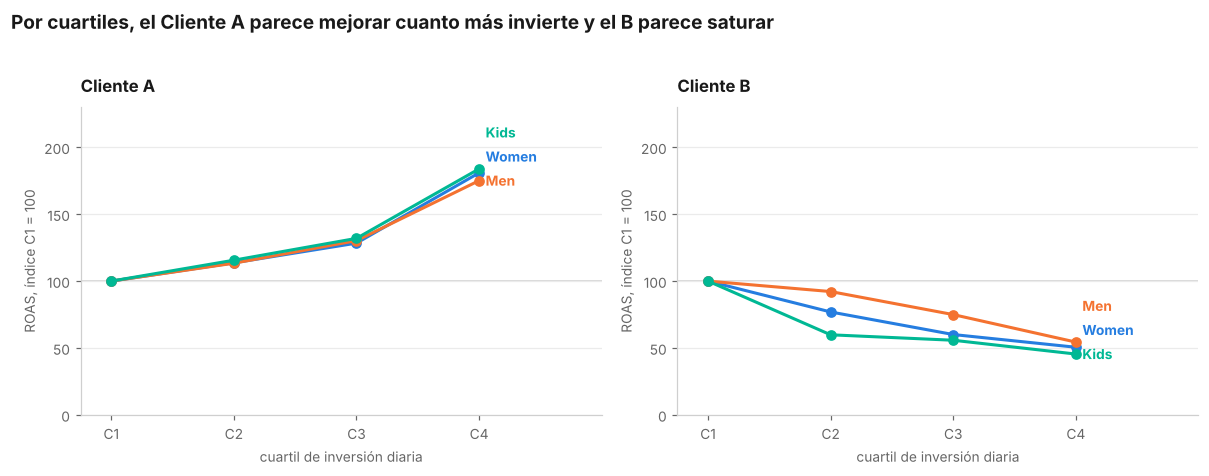

In [9]:
def etiquetas_a_la_derecha(eje, puntos, x, separacion):
    """Escribe el nombre de cada serie al final, sin que las etiquetas se pisen.

    Cuando dos series acaban casi en el mismo valor, los textos se superponen y
    no se lee ninguno. Se ordenan de menor a mayor y se separa cada una de la
    anterior lo justo para que quepan.
    """
    colocadas = []
    for y, texto, color in sorted(puntos):
        if colocadas and y - colocadas[-1][0] < separacion:
            y = colocadas[-1][0] + separacion
        colocadas.append((y, texto, color))
    for y, texto, color in colocadas:
        eje.annotate(f"  {texto}", (x, y), color=color, fontsize=9, va="center",
                     fontweight="bold", annotation_clip=False)


fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
posicion = np.arange(4)

for eje, cliente in zip(ejes, ["Cliente A", "Cliente B"]):
    etiquetas = []
    for area in ["Women", "Men", "Kids"]:
        serie = por_cuartil.loc[(cliente, area), "roas"]
        # Indexado a C1 = 100. Los dos clientes tienen niveles de ROAS muy
        # distintos: lo que se compara aquí es la FORMA de la curva, no el
        # nivel. Dos escalas distintas en el mismo gráfico engañarían.
        indice = serie / serie.loc["C1"] * 100
        eje.plot(posicion, indice.values, marker="o", color=COLOR_AREA[area])
        # Etiqueta directa: naranja y agua no llegan a 3:1 de contraste sobre
        # blanco, así que la identidad no puede depender solo del color.
        etiquetas.append((indice.values[-1], area, COLOR_AREA[area]))

    etiquetas_a_la_derecha(eje, etiquetas, x=3, separacion=18)
    eje.axhline(100, color="#cfcfcf", linewidth=1, zorder=0)
    eje.set_title(cliente)
    eje.set_ylabel("ROAS, índice C1 = 100")
    eje.set_xlabel("cuartil de inversión diaria")
    eje.set_xticks(posicion, ["C1", "C2", "C3", "C4"])
    eje.set_xlim(-0.25, 4.0)
    eje.set_ylim(0, 230)

fig.suptitle("Por cuartiles, el Cliente A parece mejorar cuanto más invierte y el B parece saturar",
             x=0.005, ha="left", fontsize=12.5, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(INFORMES / "1_cuartiles_sobre_el_periodo.png", bbox_inches="tight", dpi=130)
plt.show()

Leído así, el informe se escribe solo: *el Cliente A no satura, es más, cuanto más invierte mejor
rinde; el Cliente B satura.* La primera mitad es falsa.

La pista está en la columna `meses_distintos` de la tabla anterior, y se ve mejor cruzando cuartil
con mes:

In [10]:
mujer_a = base[(base["cliente"] == "Cliente A") & (base["area"] == "Women")]
pd.crosstab(mujer_a["mes"].astype(str), mujer_a["cuartil"])

cuartil,C1,C2,C3,C4
mes,,,,
2025-01,31,0,0,0
2025-02,15,13,0,0
2025-03,0,0,25,6
2025-04,0,11,19,0
2025-05,0,21,10,0
2025-06,0,30,0,0
2025-07,15,16,0,0
2025-08,31,0,0,0
2025-09,0,0,30,0


Ahí está. **Cada cuartil es, casi, un conjunto de meses enteros.** Un mes cae completo en el
cuartil 1 y otro completo en el 4.

La razón es cómo se gestiona la cuenta: el presupuesto del Cliente A **se fija una vez al mes** y
dentro del mes apenas se mueve. Así que ordenar los días por inversión es, en la práctica, ordenar
los meses. Y como el presupuesto sube precisamente en los meses de más demanda —noviembre,
diciembre— el cuartil 4 está hecho de los meses con mejor ROAS del año.

Lo que mide ese gráfico no es el efecto de invertir más. Es la temporada. Es **causalidad inversa**:
no es que invertir más suba el ROAS, es que cuando el ROAS va a ser alto se invierte más.

---
## 4. La corrección: medir dentro del mes

Si el problema es que el cuartil arrastra el calendario, la solución es comparar **días del mismo
mes entre sí**. Dentro de un mes, la temporada es la misma a los dos lados de la comparación, así
que ya no puede explicar la diferencia.

Cada mes se parte por la mediana de su propia inversión diaria, y se compara el ROAS de la mitad
alta con el de la baja. Con dos condiciones:

- **Solo cuentan los meses en los que la mitad alta invierte al menos un 20 % más que la baja.** Si
  las dos invierten casi lo mismo, la comparación mide ruido, no saturación.
- Febrero de 2026 queda fuera del Cliente B: contiene la ruptura de serie de la sección 5.

In [11]:
mes = df[(df["pais"] == "ES") & (df["inversion_eur"] > 0)].copy()
mes["mes"] = mes["fecha"].dt.to_period("M")
mes = mes[~((mes["cliente"] == "Cliente B") & (mes["mes"] == pd.Period("2026-02")))]

# La mediana de cada mes, devuelta a cada fila con transform.
mes["mediana_mes"] = mes.groupby(["cliente", "area", "mes"])["inversion_eur"].transform("median")
mes["mitad"] = np.where(mes["inversion_eur"] > mes["mediana_mes"], "alta", "baja")

g = (mes.groupby(["cliente", "area", "mes", "mitad"])
     .agg(inv_dia=("inversion_eur", "mean"),
          inv=("inversion_eur", "sum"),
          ing=("valor_compras", "sum"))
     .unstack("mitad"))

comp = pd.DataFrame({
    "ratio_inversion": g[("inv_dia", "alta")] / g[("inv_dia", "baja")],
    "roas_baja": g[("ing", "baja")] / g[("inv", "baja")],
    "roas_alta": g[("ing", "alta")] / g[("inv", "alta")],
}).reset_index()
comp["var_roas_pct"] = (comp["roas_alta"] / comp["roas_baja"] - 1) * 100

UMBRAL = 1.20
validos = comp[comp["ratio_inversion"] >= UMBRAL]

prueba = (validos.groupby(["cliente", "area"])
          .agg(meses_medibles=("mes", "count"),
               meses_con_caida=("var_roas_pct", lambda s: (s < 0).sum()),
               var_roas_mediana=("var_roas_pct", "median"),
               ratio_inversion_mediano=("ratio_inversion", "median")))
prueba.round(1)

meses_medibles  meses_con_caida  var_roas_mediana  ratio_inversion_mediano
cliente   area                                                                             
Cliente A Kids                3                1              1.80                     1.40
          Men                 3                1              2.30                     1.30
          Women               3                1              4.10                     1.30
Cliente B Kids               23               23            -30.60                     2.10
          Men                 9                9            -37.50                     2.20
          Women              26               25            -26.10                     2.30

Ese es el resultado del proyecto, y tiene dos lecturas.

**La primera: el Cliente B satura de verdad y el Cliente A no.** En el B, la mitad de más inversión
rinde menos en casi todos los meses medibles de las tres áreas, con caídas de la mediana de entre
el 20 % y el 35 %. En el A, el número de meses con caída y sin caída es prácticamente el mismo y la
mediana ronda el cero: no se detecta nada.

**La segunda, y es la que no se puede saltar: la evidencia no pesa lo mismo en los dos lados.** Al
Cliente A le quedan 3 meses medibles por área y al B más de veinte. Eso no es casualidad, es la
columna `ratio_inversion_mediano`: el Cliente B mueve el presupuesto al doble de un día a otro, y
el Cliente A lo mueve un 30 % en los pocos meses en que lo revisa a mitad de mes.

Así que lo que se puede afirmar del Cliente A es **que no se detectan rendimientos decrecientes, no
que no existan**. Es ausencia de evidencia, no evidencia de ausencia. Y no vale fuera del rango de
inversión observado: nada de esto dice qué pasaría al doblar el presupuesto.

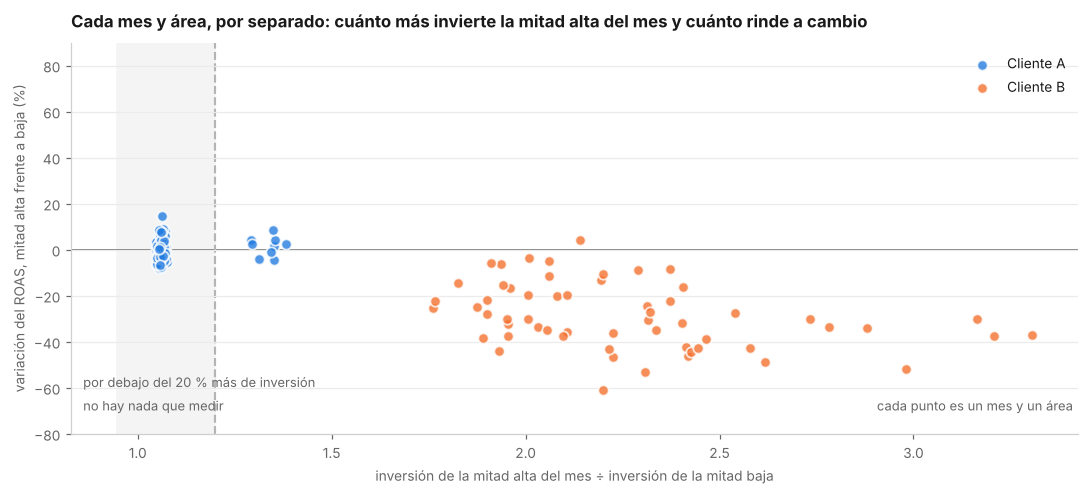

In [12]:
fig, eje = plt.subplots(figsize=(10, 4.6))

for cliente, sub in comp.groupby("cliente"):
    eje.scatter(sub["ratio_inversion"], sub["var_roas_pct"],
                s=46, alpha=0.8, color=COLOR_CLIENTE[cliente],
                edgecolor="white", linewidth=1.2, label=cliente, zorder=3)

eje.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=1)
eje.axvline(UMBRAL, color="#b4b4b4", linewidth=1.4, linestyle="--", zorder=1)
eje.axvspan(comp["ratio_inversion"].min() - 0.1, UMBRAL, color="#f4f4f4", zorder=0)

# Las anotaciones van en coordenadas del eje (0-1), no en unidades de los
# datos: así no se salen del gráfico si cambian los datos.
eje.text(0.012, 0.06, "por debajo del 20 % más de inversión\nno hay nada que medir",
         transform=eje.transAxes, fontsize=8.5, color=TINTA_SUAVE, linespacing=1.5)
eje.text(0.995, 0.06, "cada punto es un mes y un área", transform=eje.transAxes,
         fontsize=8.5, color=TINTA_SUAVE, ha="right")

eje.set_title("Cada mes y área, por separado: cuánto más invierte la mitad alta del mes y "
              "cuánto rinde a cambio", loc="left")
eje.set_xlabel("inversión de la mitad alta del mes ÷ inversión de la mitad baja")
eje.set_ylabel("variación del ROAS, mitad alta frente a baja (%)")
eje.set_ylim(-80, 90)
eje.legend(loc="upper right")
fig.tight_layout()
fig.savefig(INFORMES / "2_saturacion_dentro_del_mes.png", bbox_inches="tight", dpi=130)
plt.show()

El gráfico es el argumento entero en una imagen. Los puntos del **Cliente A** se apilan contra el
borde izquierdo, dentro de la zona gris: casi nunca mueve el presupuesto lo suficiente dentro de un
mes como para poder medir, y los pocos que la cruzan quedan repartidos alrededor del cero. Los del
**Cliente B** están todos a la derecha del umbral y casi todos por debajo del cero.

Dos clientes, el mismo método, y el resultado es el contrario. Con cuartiles sobre el periodo
completo —la sección 3— los dos habrían parecido lo mismo, o al revés.

**Una comprobación antes de darlo por bueno.** El filtro que se ha usado es `inversion_eur > 0`,
que deja dentro los días del borde de las pausas: dos euros de inversión y un ROAS de tres cifras.
Esos días caen en la mitad baja del mes y le inflan el ROAS, lo que **exageraría la caída**. Si el
hallazgo dependiera de ellos, no sería un hallazgo.

In [13]:
# Se repite la prueba descartando los días cuya inversión no llega al 10 % de
# la mediana de su propio mes, que son los del borde de las pausas.
limpio = mes[mes["inversion_eur"] >= 0.10 * mes["mediana_mes"]].copy()
limpio["mediana_mes"] = limpio.groupby(["cliente", "area", "mes"])["inversion_eur"].transform("median")
limpio["mitad"] = np.where(limpio["inversion_eur"] > limpio["mediana_mes"], "alta", "baja")

h = (limpio.groupby(["cliente", "area", "mes", "mitad"])
     .agg(inv_dia=("inversion_eur", "mean"), inv=("inversion_eur", "sum"),
          ing=("valor_compras", "sum"))
     .unstack("mitad"))
sin_residuales = pd.DataFrame({
    "ratio_inversion": h[("inv_dia", "alta")] / h[("inv_dia", "baja")],
    "var_roas_pct": ((h[("ing", "alta")] / h[("inv", "alta")])
                     / (h[("ing", "baja")] / h[("inv", "baja")]) - 1) * 100,
}).reset_index()

comprobacion = (sin_residuales[sin_residuales["ratio_inversion"] >= UMBRAL]
                .groupby(["cliente", "area"])
                .agg(meses_medibles=("mes", "count"),
                     meses_con_caida=("var_roas_pct", lambda s: (s < 0).sum()),
                     var_roas_mediana=("var_roas_pct", "median")))

prueba[["meses_medibles", "meses_con_caida", "var_roas_mediana"]].join(
    comprobacion, rsuffix="_sin_residuales").round(1)

meses_medibles  meses_con_caida  var_roas_mediana  meses_medibles_sin_residuales  meses_con_caida_sin_residuales  var_roas_mediana_sin_residuales
cliente   area                                                                                                                                                    
Cliente A Kids                3                1              1.80                              3                               1                             1.80
          Men                 3                1              2.30                              3                               1                             2.30
          Women               3                1              4.10                              3                               1                             4.10
Cliente B Kids               23               23            -30.60                             23                              23                           -29.10
          Men                 9                9            -37.50                              9                               9                           -37.50
          Women              26               25            -26.10                             26                              25                           -26.10

No dependía de ellos: las medianas se mueven un punto o dos y el número de meses con caída es el
mismo. El hallazgo aguanta.

Hacer esta comprobación cuesta diez minutos. No hacerla es la diferencia entre un resultado y un
resultado en el que se puede confiar.

---
## 5. Una ruptura de serie que no es una mejora

El ROAS del Cliente B se multiplica a principios de 2026 con la inversión diaria plana. Visto así,
es la mejor noticia del año.

Antes de contarlo como una mejora, conviene partir el ROAS en los dos factores de los que está
hecho:

$$\text{ROAS} = \frac{\text{compras}}{\text{inversión}} \times \text{valor medio por compra}$$

Si mejora la cuenta, lo normal es que se mueva algo el valor medio por compra: otro mix de producto,
menos descuento, más unidades por pedido. Si lo que cambia es **cómo se cuentan** las compras, salta
el número de compras y el valor medio se queda clavado.

In [14]:
b = df[df["cliente"] == "Cliente B"].copy()
ventana = b[(b["fecha"] >= "2025-10-01") & (b["fecha"] <= "2026-05-31")]

semanal = (ventana.groupby(["pais", pd.Grouper(key="fecha", freq="W")])
           .agg(inv=("inversion_eur", "sum"),
                compras=("compras", "sum"),
                ing=("valor_compras", "sum"))
           .reset_index())
semanal["compras_por_100eur"] = semanal["compras"] / semanal["inv"] * 100
semanal["valor_medio_compra"] = semanal["ing"] / semanal["compras"]

RUPTURA = pd.Timestamp("2026-02-11")
resumen_ruptura = (ventana.assign(
        tramo=np.where(ventana["fecha"] >= RUPTURA, "2 después", "1 antes"))
    .groupby(["pais", "tramo"])
    .agg(inv_dia=("inversion_eur", lambda s: s.sum() / len(s.index.unique())),
         compras=("compras", "sum"), inv=("inversion_eur", "sum"),
         ing=("valor_compras", "sum"))
    .assign(compras_por_100eur=lambda t: t["compras"] / t["inv"] * 100,
            valor_medio_compra=lambda t: t["ing"] / t["compras"],
            roas=lambda t: t["ing"] / t["inv"]))

resumen_ruptura[["compras_por_100eur", "valor_medio_compra", "roas"]].unstack("tramo").round(2)

compras_por_100eur           valor_medio_compra              roas          
tramo            1 antes 2 después            1 antes 2 después 1 antes 2 después
pais                                                                             
DE                  5.59     17.04              52.22     51.87    2.92      8.84
ES                  5.93     17.30              52.37     52.06    3.10      9.01
FR                 18.35     16.36              51.90     52.08    9.52      8.52
IT                 17.59     16.53              52.07     52.01    9.16      8.60
NL                  7.64     17.38              52.15     52.54    3.99      9.13

Las compras por cada 100 € se multiplican en tres mercados y el **valor medio por compra no se
mueve**: sigue en torno a 52 € antes y después, en los cinco. El ROAS sube porque se cuentan más
compras, no porque cada compra valga más.

Y la prueba que lo cierra es el gráfico: pasa **el mismo día en todos los mercados a la vez**.

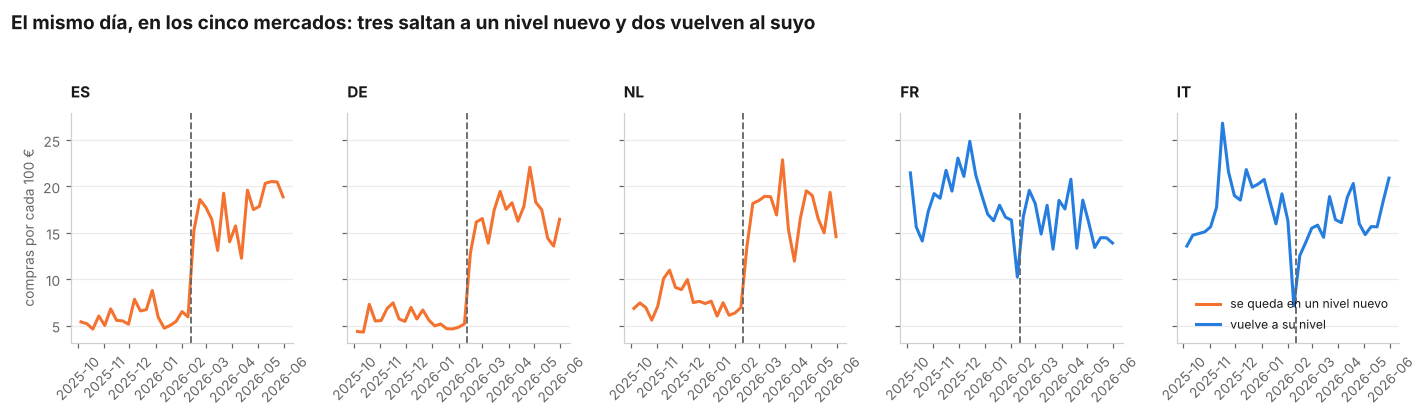

In [15]:
paises = ["ES", "DE", "NL", "FR", "IT"]
# Los tres primeros se quedan en un nivel nuevo; los dos últimos vuelven al suyo.
GRUPO = {"ES": NARANJA, "DE": NARANJA, "NL": NARANJA, "FR": AZUL, "IT": AZUL}

fig, ejes = plt.subplots(1, 5, figsize=(13, 3.6), sharey=True, sharex=True)

for eje, pais in zip(ejes, paises):
    sub = semanal[semanal["pais"] == pais]
    eje.plot(sub["fecha"], sub["compras_por_100eur"], color=GRUPO[pais])
    eje.axvline(RUPTURA, color=TINTA_SUAVE, linewidth=1.2, linestyle="--")
    eje.set_title(pais, fontsize=10)
    eje.tick_params(axis="x", rotation=45)

ejes[0].set_ylabel("compras por cada 100 €")
ejes[0].annotate("11/02", (RUPTURA, 1.5), fontsize=8, color=TINTA_SUAVE,
                 ha="right", rotation=90)

from matplotlib.lines import Line2D
ejes[-1].legend(handles=[Line2D([], [], color=NARANJA, label="se queda en un nivel nuevo"),
                         Line2D([], [], color=AZUL, label="vuelve a su nivel")],
                loc="lower right", fontsize=8)

fig.suptitle("El mismo día, en los cinco mercados: tres saltan a un nivel nuevo y dos vuelven al suyo",
             x=0.005, ha="left", fontsize=12.5, fontweight="bold", y=1.04)
fig.tight_layout()
fig.savefig(INFORMES / "3_ruptura_de_serie.png", bbox_inches="tight", dpi=130)
plt.show()

Ninguna acción comercial ocurre el mismo día en cinco países con el mismo salto. Esto es un cambio
de medición: casi con seguridad, en ES, DE y NL se estaban **contando compras de menos** y el 11 de
febrero se corrigió. Si es así, el periodo anómalo es el anterior, no el posterior.

**Lo que esto cambia en el análisis:**

- El ×3 del ROAS **no entra como hallazgo de mejora**. Está fechado, acotado a tres mercados y
  descartado como fenómeno comercial, que ya es bastante; pero la causa es una conversación con
  quien gestiona la cuenta, no otra consulta.
- **No se comparan ROAS a los dos lados del 11/02/2026** en esos tres mercados. Cualquier periodo
  que cruce esa fecha mezcla dos formas de contar, y fabricaría conclusiones sin que nada falle.
- Por eso la sección 4 excluye febrero de 2026 y la comparativa entre clientes termina en enero.

Es el único hallazgo del proyecto que se queda **en suspenso a propósito**. Un análisis que no sabe
decir "esto todavía no lo sé" es un análisis que inventa.

---
## 6. ROAS medio y ROAS marginal no dicen lo mismo

Última pieza, y la que tiene consecuencia directa en un reparto de presupuesto. La pregunta de
negocio nunca es "qué área rinde mejor": es **"dónde pongo el euro siguiente"**. No son la misma
pregunta y no tienen por qué tener la misma respuesta.

El ROAS medio responde a la primera. A la segunda responde el **ROAS marginal**: cuánto devuelven
los euros *de más* que se invierten en los días altos del mes.

$$\text{ROAS marginal} = \frac{\text{ingresos de la mitad alta} - \text{ingresos de la mitad baja}}{\text{inversión de la mitad alta} - \text{inversión de la mitad baja}}$$

(todo en medias por día, para que las dos mitades sean comparables)

In [16]:
# Ventana de un régimen de inversión estable y anterior a la ruptura.
v = mes[(mes["cliente"] == "Cliente B")
        & (mes["mes"] >= pd.Period("2025-10"))
        & (mes["mes"] <= pd.Period("2026-01"))]

m = (v.groupby(["area", "mitad"])
     .agg(inv_dia=("inversion_eur", "mean"), ing_dia=("valor_compras", "mean"))
     .unstack("mitad"))

marginal = pd.DataFrame({
    "inversion_dia": v.groupby("area")["inversion_eur"].mean(),
    "roas_medio": (v.groupby("area")["valor_compras"].sum()
                   / v.groupby("area")["inversion_eur"].sum()),
    "roas_marginal": ((m[("ing_dia", "alta")] - m[("ing_dia", "baja")])
                      / (m[("inv_dia", "alta")] - m[("inv_dia", "baja")])),
})
marginal["euro_extra_devuelve"] = marginal["roas_marginal"].round(2)
marginal.round(2)

,inversion_dia,roas_medio,roas_marginal,euro_extra_devuelve
area,,,,
Kids,407.57,2.80,1.87,1.87
Men,347.02,2.76,1.32,1.32
Women,"1,231.02",3.27,1.40,1.40


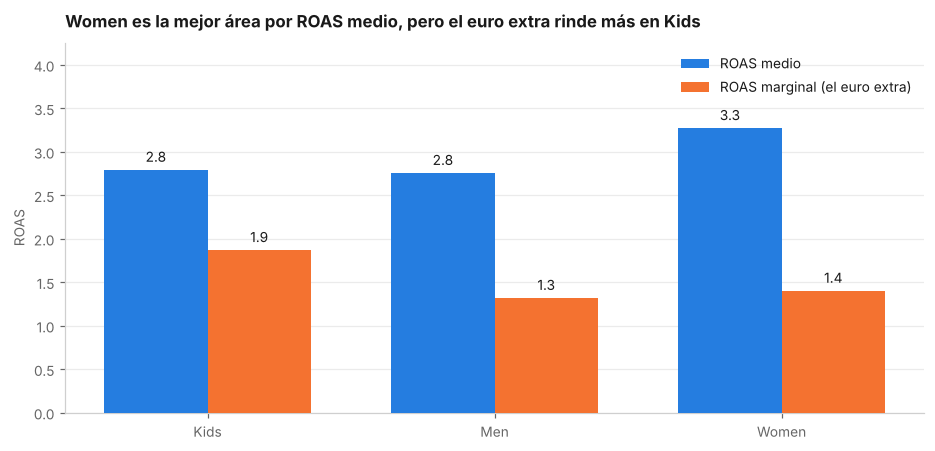

In [17]:
fig, eje = plt.subplots(figsize=(8.6, 4.2))

areas = marginal.index.tolist()
x = np.arange(len(areas))
ancho = 0.36

for desplazamiento, columna, color, etiqueta in [
        (-ancho / 2, "roas_medio", AZUL, "ROAS medio"),
        (+ancho / 2, "roas_marginal", NARANJA, "ROAS marginal (el euro extra)")]:
    valores = marginal[columna].values
    barras = eje.bar(x + desplazamiento, valores, ancho, color=color, label=etiqueta,
                     zorder=3)
    # Etiqueta directa sobre cada barra: el naranja no llega a 3:1 de
    # contraste sobre blanco, así que el valor va escrito.
    eje.bar_label(barras, fmt="%.1f", padding=3, fontsize=9, color=TINTA)

eje.set_xticks(x, areas)
eje.set_ylabel("ROAS")
eje.set_ylim(0, max(marginal["roas_medio"]) * 1.3)

# Título calculado, no escrito a mano: si los datos cambian, el titular
# cambia con ellos y no se queda afirmando algo que ya no se cumple.
mejor_medio = marginal["roas_medio"].idxmax()
mejor_marginal = marginal["roas_marginal"].idxmax()
if mejor_medio != mejor_marginal:
    titulo = (f"{mejor_medio} es la mejor área por ROAS medio, pero el euro extra "
              f"rinde más en {mejor_marginal}")
else:
    titulo = "El euro extra devuelve bastante menos que el euro medio, en las tres áreas"
eje.set_title(titulo, loc="left")
eje.legend(loc="upper right")
fig.tight_layout()
fig.savefig(INFORMES / "4_roas_medio_y_marginal.png", bbox_inches="tight", dpi=130)
plt.show()

En las tres áreas el euro extra devuelve bastante menos que el euro medio. Es la misma saturación de
la sección 4, dicha en la unidad en la que se decide un presupuesto.

Y hay algo más, que es lo que un informe hecho solo con el ROAS medio se habría perdido: **el área
que mejor rinde de media no es la que mejor absorbe el euro siguiente.** El orden de las áreas
cambia según cuál de las dos preguntas se esté respondiendo, así que recomendar más presupuesto
para "la que mejor va" apuntaría al área equivocada. **Para repartir presupuesto manda el
marginal.**

Con una salvedad que hay que decir en voz alta: **un ROAS marginal alto no significa rentable.** El
margen del producto no está en estos datos, y un ROAS de 4 puede ser pérdida en una categoría y
beneficio en otra.

---
## Conclusiones

1. **El Cliente B tiene rendimientos decrecientes y en el Cliente A no se detectan**, medido dentro
   de cada mes y en las tres áreas. Con cuartiles sobre el periodo completo, los dos habrían
   parecido iguales o al revés.
2. **Cuando el presupuesto se fija mes a mes, un cuartil de inversión es un mes disfrazado.** Antes
   de leer un cuartil hay que cruzarlo con el mes; si cada cuartil es casi un mes entero, la
   saturación se mide dentro del mes.
3. **La forma de gestionar cada cuenta decide cuánto se puede medir en ella.** El Cliente A apenas
   mueve el presupuesto dentro del mes, y por eso le quedan 3 meses medibles por área frente a más
   de veinte del B. La conclusión sobre el A es débil, y decirlo forma parte del resultado.
4. **El salto de ROAS de 2026 en el Cliente B es un cambio de medición, no una mejora.** Mismo día
   en cinco mercados, salto en el número de compras, valor medio por compra plano.
5. **El euro extra devuelve menos que el euro medio en las tres áreas del Cliente B.** Un reparto de
   presupuesto hecho con el ROAS medio apuntaría al área equivocada.

## Limitaciones

- **Los datos son sintéticos** (ver la nota del principio). Reproducen la estructura del problema
  real, no sus cifras.
- **Atribución diaria.** Los días de poca inversión reciben compras atribuidas a clics de días
  anteriores, lo que infla su ROAS. Empuja en la misma dirección que el hallazgo de saturación, así
  que parte de la caída medida puede venir de ahí. Con datos diarios no se puede separar.
- **Rango de inversión observado.** Nada de esto dice qué pasaría fuera de los niveles de inversión
  que hay en los datos.
- **Falta el margen.** Sin margen de producto, ningún ROAS de aquí se puede traducir en beneficio.
- **La causa de la ruptura de serie no está confirmada**, solo fechada y acotada.
- Las pausas del Cliente B y las filas con compras sin impresiones se conservan en la base de datos
  y se excluyen en los cálculos donde distorsionan. No se han borrado: un dato raro documentado vale
  más que un dato raro desaparecido.